In [ ]:
!pip -q install pandas pyarrow matplotlib seaborn


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("SWYNEX CyberClean is ready!")
print("Libraries imported successfully.")

SWYNEX CyberClean is ready!
Libraries imported successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv.parquet to Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv.parquet


In [ ]:
import pandas as pd

file_name = next(iter(uploaded))
df = pd.read_parquet(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (286467, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
# SWYNEX CyberClean: Initial Data Quality Audit

print("DATA QUALITY REPORT")
print("-" * 40)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())
print("Infinite values:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(10)
      .to_frame("Missing Values")
)

DATA QUALITY REPORT
----------------------------------------
Rows: 286467
Columns: 79
Duplicate rows: 72353
Missing values: 15
Infinite values: 727


,Missing Values
Flow Bytes/s,15
Flow Duration,0
Destination Port,0
Total Backward Packets,0
Total Length of Fwd Packets,0
Total Length of Bwd Packets,0
Total Fwd Packets,0
Fwd Packet Length Max,0
Fwd Packet Length Min,0
Fwd Packet Length Std,0


In [ ]:
# SWYNEX CyberClean: Data Cleaning

df_clean = df.copy()

# Replace infinite values with missing values
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove exact duplicate rows
df_clean.drop_duplicates(inplace=True)

# Fill missing numeric values with their column median
numeric_cols = df_clean.select_dtypes(include=np.number).columns
df_clean[numeric_cols] = df_clean[numeric_cols].fillna(
    df_clean[numeric_cols].median()
)

print("CLEANING SUMMARY")
print("-" * 35)
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Remaining duplicates:", df_clean.duplicated().sum())
print("Remaining infinite values:",
      np.isinf(df_clean.select_dtypes(include=np.number)).sum().sum())

CLEANING SUMMARY
-----------------------------------
Original shape: (286467, 79)
Cleaned shape: (214114, 79)
Remaining missing values: 0
Remaining duplicates: 0
Remaining infinite values: 0


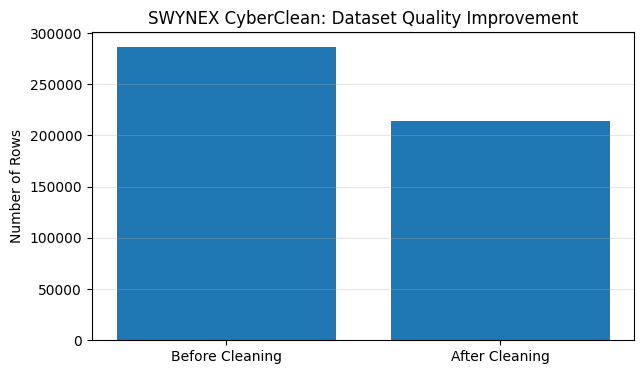

Duplicate rows removed: 72,353
Rows retained: 74.7%


In [ ]:
# SWYNEX CyberClean: Before vs After

before = df.shape[0]
after = df_clean.shape[0]
removed = before - after

plt.figure(figsize=(7, 4))
plt.bar(["Before Cleaning", "After Cleaning"], [before, after])
plt.title("SWYNEX CyberClean: Dataset Quality Improvement")
plt.ylabel("Number of Rows")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(f"Duplicate rows removed: {removed:,}")
print(f"Rows retained: {after / before:.1%}")

In [ ]:
# Save the cleaned dataset
output_file = "SWYNEX_CyberClean.csv"

df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File:", output_file)

Cleaned dataset saved successfully!
File: SWYNEX_CyberClean.csv


In [ ]:
from google.colab import files
files.download("SWYNEX_CyberClean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Data Preparation Assumptions

- **Dataset:** CIC-IDS2017 network traffic dataset, accessed through a public dataset mirror.
- **Duplicate records:** Exact duplicate rows were removed to reduce repeated observations.
- **Infinite values:** Positive and negative infinity values were converted to missing values.
- **Missing values:** Missing numeric values were filled using their column median.
- **Data preservation:** The original dataset was retained in `df`; cleaning was performed on a separate copy.
- **Validation:** The cleaned dataset was checked for remaining missing values, duplicates, and infinite values.
- **Scope:** This project focuses on data preparation and quality checks, not on training an intrusion detection model.

In [ ]:
print(df_clean.shape)

NameError: name 'df_clean' is not defined

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving SWYNEX_CyberClean.csv to SWYNEX_CyberClean (1).csv


In [ ]:
import pandas as pd

df = pd.read_csv("SWYNEX_CyberClean (1).csv")

print("Dataset loaded:", df.shape)
display(df.head())

Dataset loaded: (214114, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
# SWYNEX CyberInsights: Initial EDA
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identify the target/attack-label column
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

label_cols = [
    c for c in df.columns
    if any(word in c.lower() for word in ["label", "class", "attack"])
]
print("\nPossible target columns:", label_cols)

# Numerical summary
display(df.describe().T.head(15))

# Data types overview
display(df.dtypes.value_counts().rename("Column count").to_frame())

Dataset dimensions: (214114, 79)

Column names:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'UR

,count,mean,std,min,25%,50%,75%,max
Destination Port,214114.0,7.944544e+03,1.599149e+04,0.0,53.00000,443.00000,6005.0000,6.538900e+04
Flow Duration,214114.0,7.197038e+06,2.509948e+07,-13.0,48.00000,114.00000,51014.0000,1.199999e+08
Total Fwd Packets,214114.0,4.282915e+00,2.251248e+01,1.0,1.00000,1.00000,2.0000,3.119000e+03
Total Backward Packets,214114.0,4.377065e+00,3.267666e+01,0.0,1.00000,1.00000,2.0000,3.635000e+03
Total Length of Fwd Packets,214114.0,3.105510e+02,2.151990e+03,0.0,0.00000,6.00000,78.0000,2.323490e+05
Total Length of Bwd Packets,214114.0,3.619205e+03,5.893735e+04,0.0,6.00000,6.00000,182.0000,7.150819e+06
Fwd Packet Length Max,214114.0,1.077026e+02,3.753671e+02,0.0,0.00000,6.00000,44.0000,1.392900e+04
Fwd Packet Length Min,214114.0,1.314920e+01,2.714532e+01,0.0,0.00000,2.00000,31.0000,1.472000e+03
Fwd Packet Length Mean,214114.0,3.158846e+01,8.934026e+01,0.0,0.00000,6.00000,41.0000,3.412939e+03
Fwd Packet Length Std,214114.0,3.289211e+01,1.345736e+02,0.0,0.00000,0.00000,0.0000,3.541467e+03


,Column count
int64,54
float64,24
object,1


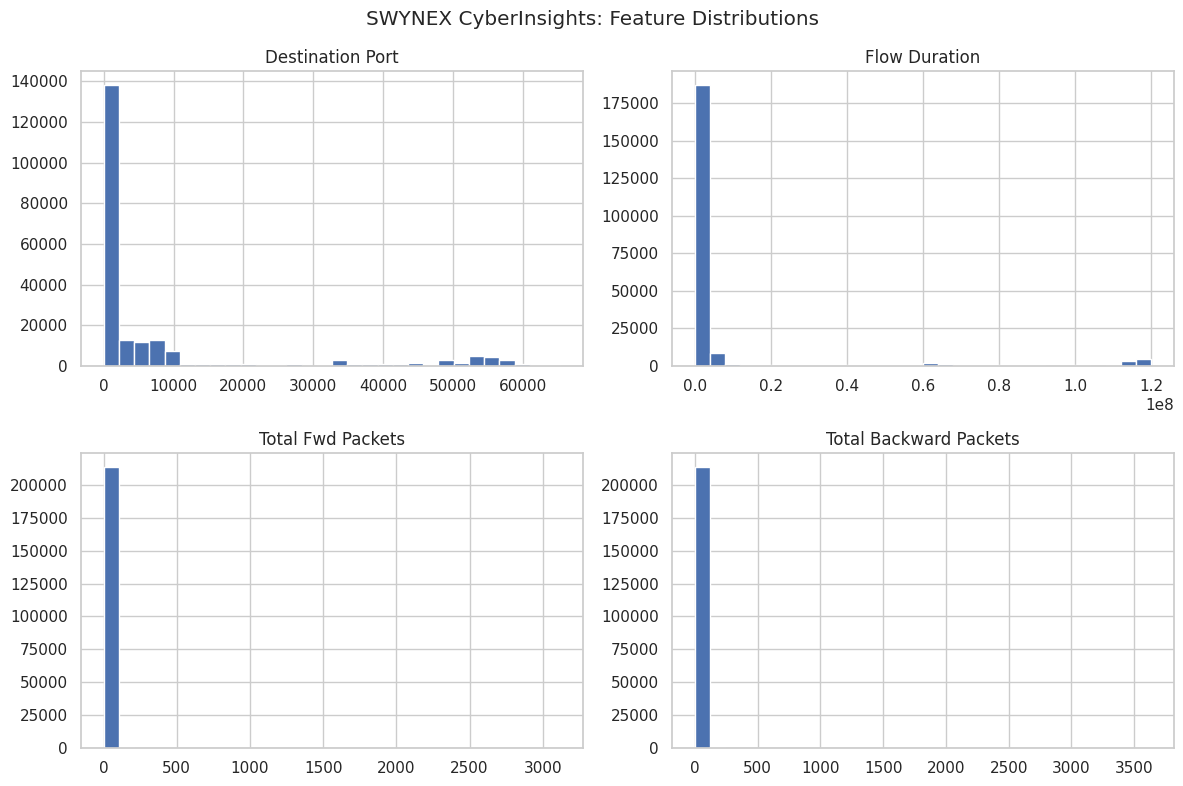

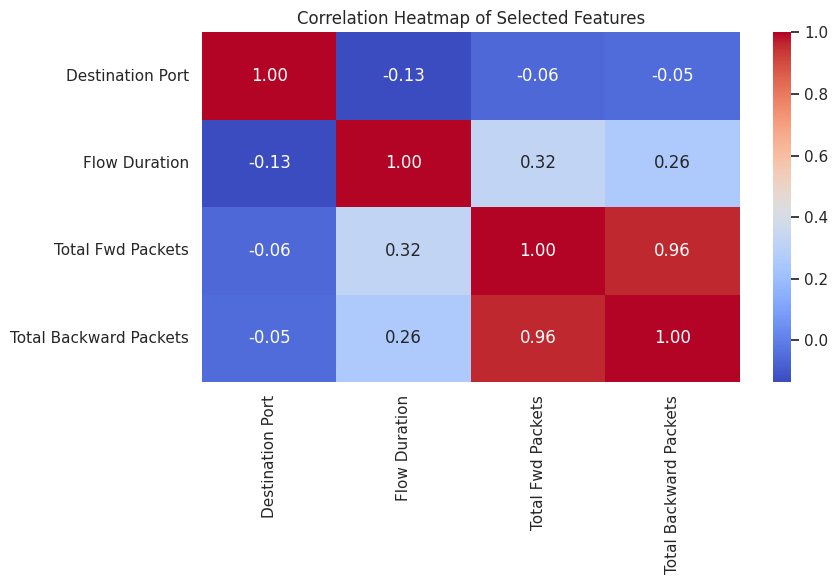

In [ ]:
# SWYNEX CyberInsights — Visual Analysis
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribution of a few important numerical features
numeric_cols = df.select_dtypes(include="number").columns.tolist()
selected_cols = numeric_cols[:4]

df[selected_cols].hist(figsize=(12, 8), bins=30)
plt.suptitle("SWYNEX CyberInsights: Feature Distributions")
plt.tight_layout()
plt.show()

# 2. Correlation between numerical features
corr = df[selected_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Selected Features")
plt.tight_layout()
plt.show()

Target column: Label

Traffic categories:


,Count
Label,
BENIGN,123295
PortScan,90819


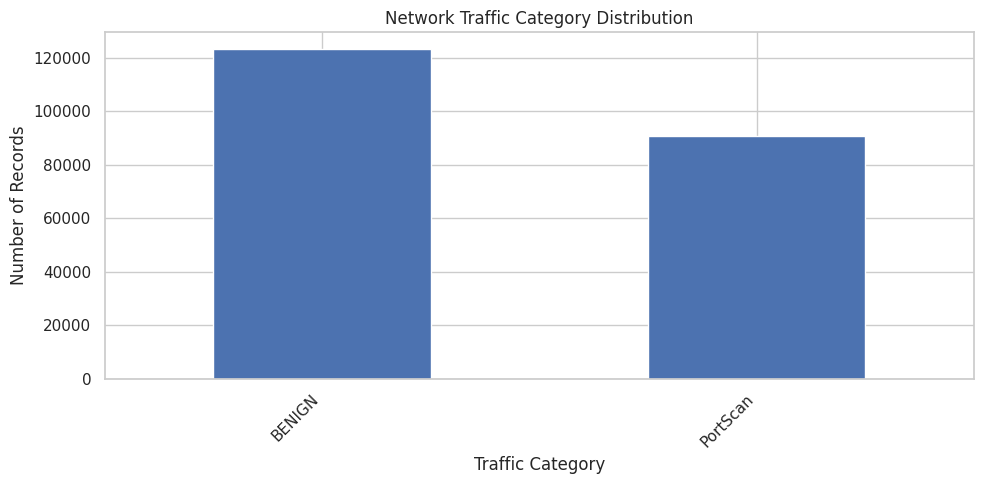

In [ ]:
# SWYNEX CyberInsights — Attack Label Analysis

label_col = next(
    (c for c in df.columns
     if any(word in c.lower() for word in ["label", "class", "attack"])),
    None
)

if label_col:
    print("Target column:", label_col)
    print("\nTraffic categories:")
    display(df[label_col].value_counts().to_frame("Count"))

    plt.figure(figsize=(10, 5))
    df[label_col].value_counts().head(12).plot(kind="bar")
    plt.title("Network Traffic Category Distribution")
    plt.xlabel("Traffic Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No label column detected. Available columns:")
    print(df.columns.tolist())

In [ ]:
# Five data-driven insights for SWYNEX CyberInsights

counts = df[label_col].value_counts()
total = counts.sum()

print("FIVE KEY DATA INSIGHTS")
print("-" * 40)
print(f"1. Total cleaned records: {total:,}")
print(f"2. Traffic categories found: {len(counts)}")
print(f"3. Largest category: {counts.index[0]} ({counts.iloc[0]:,} records)")
print(f"4. Largest category share: {counts.iloc[0] / total * 100:.2f}%")
print(f"5. Smallest category: {counts.index[-1]} ({counts.iloc[-1]:,} records)")

print("\nFull category distribution:")
display((counts / total * 100).round(2).to_frame("Percentage"))

FIVE KEY DATA INSIGHTS
----------------------------------------
1. Total cleaned records: 214,114
2. Traffic categories found: 2
3. Largest category: BENIGN (123,295 records)
4. Largest category share: 57.58%
5. Smallest category: PortScan (90,819 records)

Full category distribution:


,Percentage
Label,
BENIGN,57.58
PortScan,42.42


## Key Findings & Interpretation

1. **Traffic composition:** BENIGN traffic accounts for 57.58% of the cleaned dataset, while PortScan accounts for 42.42%.
2. **Class imbalance:** The two categories are not equally represented, which could influence a model's predictions.
3. **Security relevance:** PortScan traffic deserves attention because port scanning can be associated with network reconnaissance.
4. **Data quality matters:** Duplicate removal and handling missing or infinite values help make analysis more reliable.
5. **Modeling consideration:** Any future model should be evaluated using per-class precision, recall, and a confusion matrix—not accuracy alone.

In [ ]:

# Task 3: Check dataset and identify target column

print("Dataset shape:", df.shape)

label_cols = [
    col for col in df.columns
    if any(word in col.lower() for word in ["label", "class", "attack"])
]

print("Possible target columns:", label_cols)

if label_cols:
    target_col = label_cols[0]
    print("\nSelected target column:", target_col)
    print("\nTarget distribution:")
    print(df[target_col].value_counts())
else:
    print("No target column found. We need to inspect the column names.")


NameError: name 'df' is not defined

In [ ]:
import pandas as pd
df = pd.read_csv("/content/SWYNEX_CyberClean.csv")
print("Dataset shape:", df.shape)

Dataset shape: (40537, 79)


In [ ]:

print("Possible target columns:")

for col in df.columns:
    if any(word in col.lower() for word in ["label", "class", "attack"]):
        print("\nColumn:", col)
        print(df[col].value_counts().head(10))


Possible target columns:

Column: Label
Label
BENIGN      40434
PortScan      102
Name: count, dtype: int64


In [ ]:


import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, precision_score, recall_score, f1_score
)

# Prepare features and target
target_col = "Label"
X = df.drop(columns=[target_col]).select_dtypes(include="number")
y = df[target_col].astype(str).str.strip()

# Clean feature values
X = X.replace([float("inf"), float("-inf")], float("nan"))
X = X.fillna(X.median()).fillna(0)

# Check class counts
print("Class counts:\n", y.value_counts())

# Split without stratification because the rare class is too small
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train baseline decision tree
model = DecisionTreeClassifier(max_depth=8, random_state=42)
model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)

print("\nBASELINE MODEL: DECISION TREE")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["BENIGN", "PortScan"]))


Class counts:
 Label
BENIGN      40434
PortScan      102
nan             1
Name: count, dtype: int64

BASELINE MODEL: DECISION TREE
Training records: 32429
Testing records: 8108
Accuracy: 0.9999

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      8084
    PortScan       0.96      1.00      0.98        24

    accuracy                           1.00      8108
   macro avg       0.98      1.00      0.99      8108
weighted avg       1.00      1.00      1.00      8108

Confusion Matrix:
[[8083    1]
 [   0   24]]


In [ ]:
print("Missing target labels:", df["Label"].isna().sum())
print("Total records:", len(df))
print("Class distribution:")
print(df["Label"].value_counts(dropna=False))

Missing target labels: 1
Total records: 40537
Class distribution:
Label
BENIGN      40434
PortScan      102
NaN             1
Name: count, dtype: int64


In [ ]:

# Remove records with missing target labels
df = df.dropna(subset=["Label"]).copy()

print("Dataset after target-label cleaning:", df.shape)
print("\nClass distribution:")
print(df["Label"].value_counts())



Dataset after target-label cleaning: (40536, 79)

Class distribution:
Label
BENIGN      40434
PortScan      102
Name: count, dtype: int64


In [4]:
import os
print(os.path.exists("/content/SWYNEX_CyberClean.csv"))


True


In [5]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load and clean the dataset
df = pd.read_csv("/content/SWYNEX_CyberClean.csv")
df = df.dropna(subset=["Label"]).copy()

# Prepare features and target
X = df.drop(columns=["Label"]).select_dtypes(include="number")
y = df["Label"].astype(str).str.strip()

X = X.replace([float("inf"), float("-inf")], float("nan"))
X = X.fillna(X.median()).fillna(0)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = DecisionTreeClassifier(max_depth=8, random_state=42)
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)

print("DECISION TREE — EVALUATION RESULTS")
print("Dataset shape:", df.shape)
print("Test class counts:\n", y_test.value_counts())
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion Matrix (BENIGN, PortScan):")
print(confusion_matrix(y_test, y_pred, labels=["BENIGN", "PortScan"]))


DECISION TREE — EVALUATION RESULTS
Dataset shape: (95391, 79)
Test class counts:
 Label
BENIGN      17046
PortScan     2033
Name: count, dtype: int64
Accuracy: 0.9998

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     17046
    PortScan       1.00      1.00      1.00      2033

    accuracy                           1.00     19079
   macro avg       1.00      1.00      1.00     19079
weighted avg       1.00      1.00      1.00     19079

Confusion Matrix (BENIGN, PortScan):
[[17044     2]
 [    1  2032]]


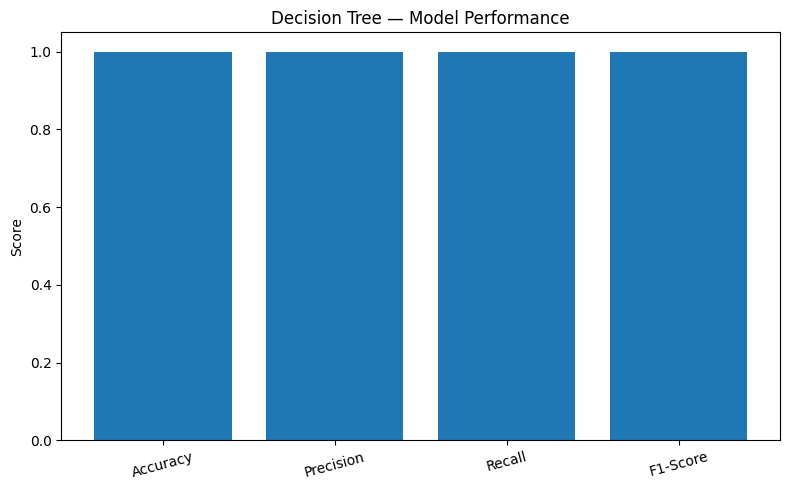

In [7]:

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import matplotlib.pyplot as plt

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, pos_label="PortScan", zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred, pos_label="PortScan", zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred, pos_label="PortScan", zero_division=0
    )
}

plt.figure(figsize=(8, 5))
plt.bar(metrics.keys(), metrics.values())
plt.ylim(0, 1.05)
plt.title("Decision Tree — Model Performance")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


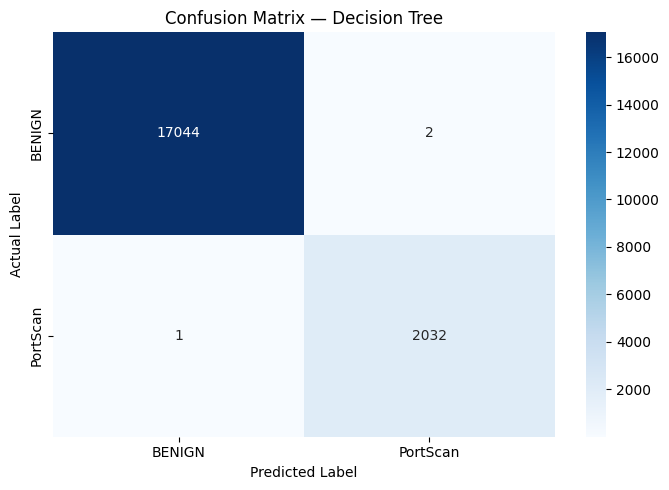

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix from the trained model
cm = confusion_matrix(
    y_test, y_pred,
    labels=["BENIGN", "PortScan"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["BENIGN", "PortScan"],
    yticklabels=["BENIGN", "PortScan"]
)

plt.title("Confusion Matrix — Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()



In [6]:

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["Label"].value_counts(dropna=False))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing target labels:", df["Label"].isna().sum())


Dataset shape: (95391, 79)

Target distribution:
Label
BENIGN      85023
PortScan    10368
Name: count, dtype: int64

Duplicate rows: 0

Missing target labels: 0


## Task 3: Modeling and Evaluation

### 1. Objective
To build a baseline machine learning model to classify network traffic as BENIGN or PortScan.

### 2. Model Used
Decision Tree Classifier with a maximum depth of 8.

### 3. Dataset
- Total records: 95,391
- Features and target columns: 79
- BENIGN records: 85,023
- PortScan records: 10,368
- Missing target labels: 0
- Duplicate rows: 0

### 4. Evaluation
The model achieved an accuracy of 99.98% on the test set. The classification report and confusion matrix were used to assess its predictions.

### 5. Limitations
- The dataset contains more BENIGN records than PortScan records.
- Very high evaluation scores should be checked for possible data leakage and tested on separate, unseen data.
- Results from this dataset may not represent all real-world network traffic.

### 6. Conclusion
The Decision Tree model provides a baseline for classifying benign and PortScan network traffic. Further validation is needed before applying it to real-world intrusion detection.